In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Se dispone de las tres estimaciones (optimista, más probable, pesimista; en semanas) de cada actividad. Algunas actividades tienen duración fija (las tres estimaciones coinciden).

In [4]:
pregunta_1 = "1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  "
pregunta_2 = "2. Determine el camino crítico y la duración media del proyecto.  "
pregunta_3 = "3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  "
pregunta_4 = "4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  

2. Determine el camino crítico y la duración media del proyecto.  

3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  

4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b
    ('A'     , '---'      , 3, 4, 5),
    ('B'     , '---'      , 6, 6, 6),
    ('C'     , 'A,B'      , 1, 2, 3),
    ('D'     , 'C'        , 1, 1, 7),
    ('E'     , 'C'        , 2, 5, 8),
    ('F'     , 'C'        , 1, 2, 5),
    ('G'     , 'E,F'      , 3, 3, 9),
    ('H'     , 'D,E'      , 6, 6, 6),
    ('I'     , 'G'        , 1, 3, 5),
], columns=['activity', 'predecessor', 'a', 'm', 'b']).set_index('activity')
datos_enunciado

,predecessor,a,m,b
activity,,,,
A,---,3,4,5
B,---,6,6,6
C,"A,B",1,2,3
D,C,1,1,7
E,C,2,5,8
F,C,1,2,5
G,"E,F",3,3,9
H,"D,E",6,6,6
I,G,1,3,5


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
    'I': 'Pruebas de integración',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización
I,Pruebas de integración


# Resolución

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule la duración media y la varianza de cada actividad. ¿Qué varianza tienen las actividades de duración fija?  

In [8]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = datos_proyecto.eval('(a + 4 * m + b) / 6').round().astype(int)
datos_proyecto['variance'] = datos_proyecto.eval('((b - a) / 6) ** 2')
datos_proyecto

,predecessor,a,m,b,duration,variance
activity,,,,,,
A,---,3,4,5,4,0.111111
B,---,6,6,6,6,0.000000
C,"A,B",1,2,3,2,0.111111
D,C,1,1,7,2,1.000000
E,C,2,5,8,5,1.000000
F,C,1,2,5,2,0.444444
G,"E,F",3,3,9,4,1.000000
H,"D,E",6,6,6,6,0.000000
I,G,1,3,5,3,0.444444


Cuando $a = m = b$ la varianza es $(b-a)^2/36 = 0$: la actividad no aporta incertidumbre, aunque sí aporta duración.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Determine el camino crítico y la duración media del proyecto.  

In [10]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

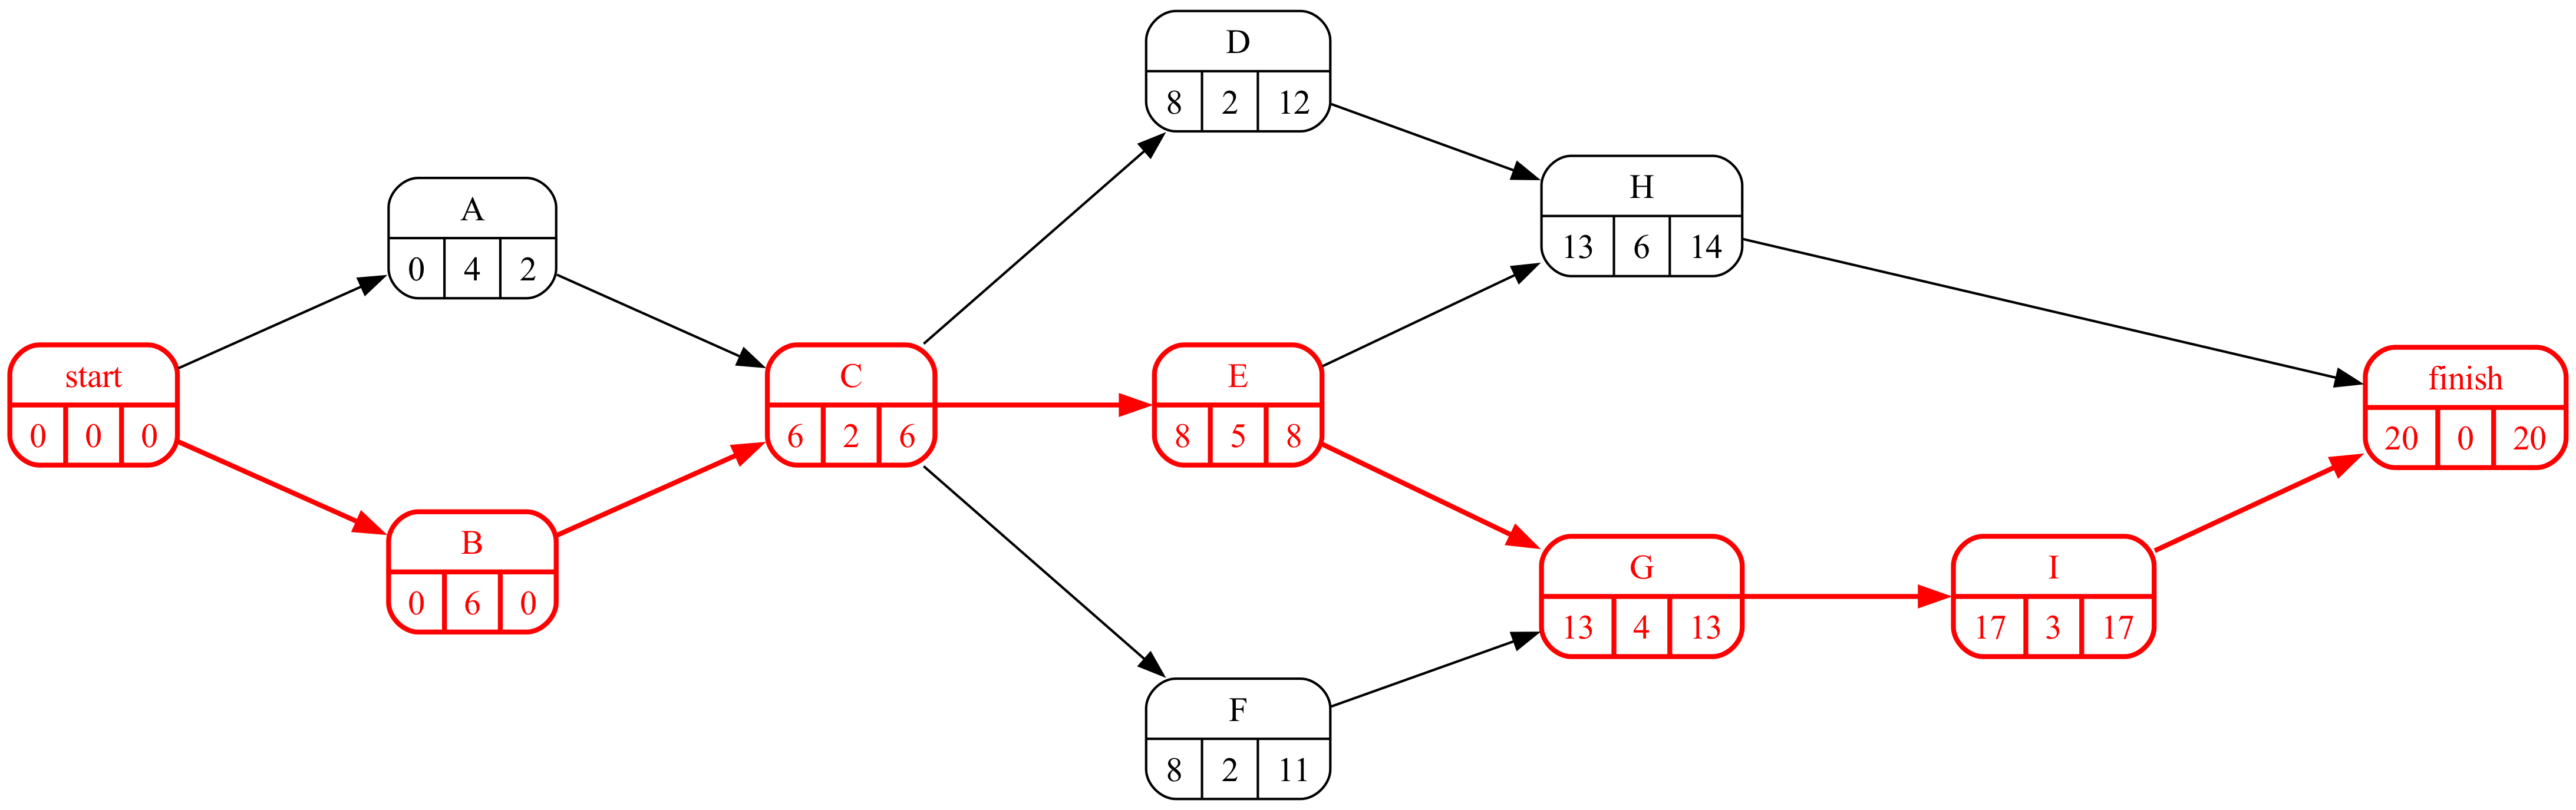

In [11]:
#| fig-cap: "Grafo Roy con duraciones medias y camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [12]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'La duración media del proyecto es {duracion_media} semanas.')

- Route_6 :	B, C, E, G, I <br> 

La duración media del proyecto es 20 semanas.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Calcule la varianza del proyecto. ¿Qué actividades contribuyen a ella? ¿Contribuye la actividad no crítica más variable? ¿Y las críticas de duración fija?  

In [14]:
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['variance'])
display(varianza_rutas)
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
contribuyen = datos_proyecto.loc[criticas, 'variance']
mas_variable_no_critica = datos_proyecto['variance'].drop(criticas).idxmax()
pd.DataFrame({'crítica': datos_proyecto.index.isin(criticas), 'varianza': datos_proyecto['variance']}).T

,Activities,Variance
Route_6,"B, C, E, G, I",2.56


activity,A,B,C,D,E,F,G,H,I
crítica,False,True,True,False,True,False,True,False,True
varianza,0.111111,0.0,0.111111,1.0,1.0,0.444444,1.0,0.0,0.444444


In [15]:
Markdown(f'''La varianza del proyecto, {desviacion_proyecto**2:.3f}, es la suma de las varianzas de las actividades críticas: sólo contribuyen {", ".join(a for a in criticas if datos_proyecto.loc[a, "variance"] > 0)}. La actividad no crítica más variable, {mas_variable_no_critica} (varianza {datos_proyecto.loc[mas_variable_no_critica, "variance"]:.3f}), no cuenta en la aproximación PERT porque no está en la ruta crítica, aunque Monte Carlo mostraría que sí influye si su holgura es pequeña. Las críticas de duración fija ({", ".join(a for a in criticas if datos_proyecto.loc[a, "variance"] == 0) or "ninguna"}) aportan duración pero no varianza.''')

La varianza del proyecto, 2.556, es la suma de las varianzas de las actividades críticas: sólo contribuyen C, E, G, I. La actividad no crítica más variable, D (varianza 1.000), no cuenta en la aproximación PERT porque no está en la ruta crítica, aunque Monte Carlo mostraría que sí influye si su holgura es pequeña. Las críticas de duración fija (B) aportan duración pero no varianza.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Si pudiera reducir a cero la varianza de una sola actividad, ¿cuál elegiría para hacer el plazo más predecible? ¿Y cuál para acortarlo?  

In [17]:
mas_variable_critica = contribuyen.idxmax()
mas_larga_critica = datos_proyecto.loc[criticas, 'duration'].idxmax()
Markdown(f'Para hacer el plazo más predecible conviene atacar la varianza de {mas_variable_critica} (la crítica de mayor varianza); '
         f'para acortarlo, la duración de alguna crítica, por ejemplo {mas_larga_critica}, la más larga. Reducir la varianza de una no crítica no cambia nada en el análisis PERT.')

Para hacer el plazo más predecible conviene atacar la varianza de E (la crítica de mayor varianza); para acortarlo, la duración de alguna crítica, por ejemplo B, la más larga. Reducir la varianza de una no crítica no cambia nada en el análisis PERT.